# Does AlexNet show human-like perceptual effects?

**Reading:** Jacob, G., Pramod, R. T., Katti, H., & Arun, S. P. (2021). Qualitative similarities and differences in visual object representations between brains and deep networks. *Nature Communications, 12*, 1872.

Jacob et al. tested whether deep networks show 13 classic effects from human perception and neuroscience, in a **trained** and an **untrained** network. Today you test two of them in AlexNet:

1. **Scene incongruence**
2. **Mirror confusion**

**Teamwork:** your partner has a different notebook. Section 1 is the same for both of you, section 2 is different.

**How to use this notebook:** settings in CAPITALS (e.g. `OBJECT_SIZE`) can be changed. Change them and run the cell again.

## Setup

In [1]:
import warnings; warnings.filterwarnings("ignore")
import csv
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from pathlib import Path
from PIL import Image, ImageDraw, ImageFont
import torch
from torchvision import models, transforms
device = "cpu"

**If Sciebo doesn't work:** download the Week 5 folder `scene_incongruence` and `animals_objects` from Sciebo, and upload it into a folder called `images` inside this notebook's folder (`Cognitive_Neuroscience_Update/Week5-Jacob2021`).

In [2]:
# Find the course data: on JupyterHub it is in Sciebo, on your own computer next to this notebook
def find(sciebo_folder, local_folder):
    hits = sorted(Path.home().glob(f"sciebo/*/{sciebo_folder}"))
    folder = hits[0] if hits else Path(local_folder)
    if not folder.is_dir() or not any(folder.iterdir()):
        raise FileNotFoundError(
            f"Images were not found in {folder}.\n"
            "On JupyterHub: did you connect Sciebo when starting the server, and accept the shared CNU folder?\n"
            f"On your own computer: put the folder at {local_folder}"
        )
    return folder

SCENE_DIR = find("Week5/images/scene_incongruence", "images/scene_incongruence")
IMAGE_DIR = find("Week5/images/animals_objects", "images/animals_objects")         # 48 of last week's images

In [3]:
# The trained and the untrained AlexNet, as last week
trained = models.alexnet(weights=models.AlexNet_Weights.IMAGENET1K_V1).to(device).eval()
torch.manual_seed(0)    # the same "random" weights for everyone
untrained = models.alexnet(weights=None).to(device).eval()
NETWORKS = {"trained": trained, "untrained": untrained}
CATEGORIES = models.AlexNet_Weights.IMAGENET1K_V1.meta["categories"]    # the 1,000 ImageNet names

# All images are prepared as 224 x 224 pixels; this turns them into network input
normalise = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])
what_network_sees = transforms.Compose([transforms.Resize(256), transforms.CenterCrop(224)])

LAYERS = {
    "conv1": ("features", 1), "conv2": ("features", 4), "conv3": ("features", 7),
    "conv4": ("features", 9), "conv5": ("features", 11),
    "fc6": ("classifier", 2), "fc7": ("classifier", 5), "fc8": ("classifier", 6),
}

def get_acts(model, imgs):
    # Return a dict: layer name -> activations, one row per image (flattened)
    saved = {}
    hooks = [getattr(model, part)[i].register_forward_hook(
                 lambda layer, inp, out, name=name: saved.__setitem__(name, out.flatten(1).numpy()))
             for name, (part, i) in LAYERS.items()]
    with torch.no_grad():
        model(torch.stack([normalise(img.convert("RGB")) for img in imgs]).to(device))
    for h in hooks:
        h.remove()
    return saved

def plot_layers(values, title, ylabel):
    # One line per network across the 8 layers
    plt.figure(figsize=(7, 3.5))
    for net, v in values.items():
        plt.plot(list(LAYERS), v, marker="o", label=net)
    plt.axhline(0, color="grey", lw=0.8)
    plt.ylabel(ylabel); plt.title(title); plt.legend(); plt.show()

## 1. Scene incongruence

People recognise an object faster and more accurately in a scene where it belongs (a soccer ball in a stadium) than in one where it doesn't (a soccer ball in a factory). Does the network?

We paste 49 objects onto scenes that people rated as fitting (**congruent**) or not fitting (**incongruent**), and check whether the **trained** network still names the object. The untrained network can't name anything, so it is left out here.

*Images: ObScene database (Andrade et al., 2023).*

In [4]:
pairs = list(csv.DictReader(open(SCENE_DIR / "pairs.csv")))     # object, correct labels, condition, scene
correct = {p["object"][:-4]: p["imagenet_labels"].split("; ") for p in pairs}
print(f"{len(correct)} objects, {len(pairs)} object-scene pairs")
print(sorted(correct))

def paste(obj, scene_name, size):
    # Paste the object in the centre; size = share of the image width/height
    cut = Image.open(SCENE_DIR / "objects" / f"{obj}.png")
    s = size * 224 / max(cut.size)
    cut = cut.resize((max(1, int(cut.width * s)), max(1, int(cut.height * s))))
    if scene_name == "white":
        bg = Image.new("RGB", (224, 224), "white")
    else:
        bg = what_network_sees(Image.open(SCENE_DIR / "scenes" / scene_name).convert("RGB")).resize((224, 224))
    bg.paste(cut, ((224 - cut.width) // 2, (224 - cut.height) // 2), cut)
    return bg

def top5(imgs):
    # The trained network's 5 best guesses for each image
    with torch.no_grad():
        out = trained(torch.stack([normalise(i) for i in imgs]).to(device))
    return [[CATEGORIES[k] for k in row.topk(5).indices] for row in out]

49 objects, 115 object-scene pairs
['abacus', 'apron', 'armor', 'basketball', 'beach_bucket', 'beach_umbrella', 'bicycle_bottle', 'binoculars', 'bird_house', 'bottle', 'bottle_cap', 'camera', 'chainsaw', 'cleaver', 'clock', 'colander', 'computer_monitor', 'corkscrew', 'cup_of_coffee', 'desk_microphone', 'envelope', 'eskimo_coat', 'gun', 'hat', 'knee_pads', 'laundry_basket', 'oxygen_mask', 'projector', 'punching_bag', 'racket', 'remote_control', 'safety_pin', 'saxophone', 'semaphore', 'soap_dispenser', 'soccer_ball', 'sound_speaker', 'stethoscope', 'stopwatch', 'syringe', 'tennis_ball', 'thimble', 'throne', 'torch', 'towels', 'trash_can', 'unicycle', 'weights', 'whistle']


Change the examples to see more images & change the object size to see whether this has an effect on the results

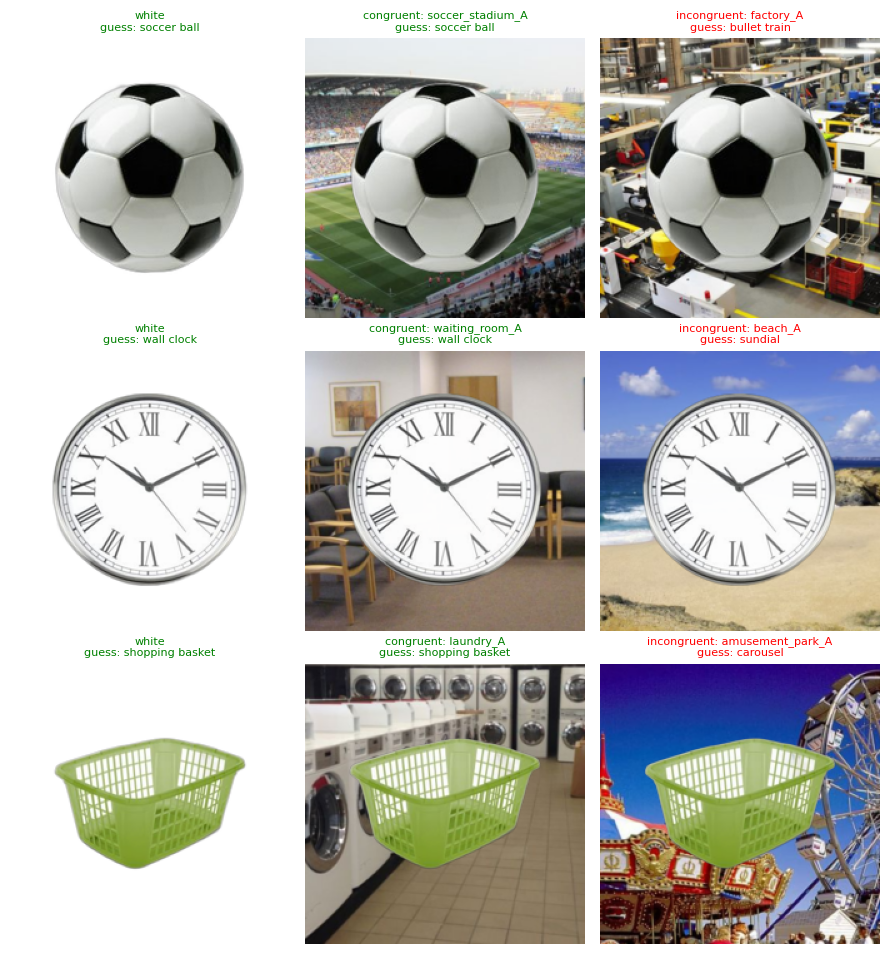

In [5]:
EXAMPLES = ["soccer_ball", "clock", "laundry_basket"]   # pick from the list above
OBJECT_SIZE = 0.7                                    # 0.7 = the object fills 70% of the image

fig, axes = plt.subplots(len(EXAMPLES), 3, figsize=(9, 3.2 * len(EXAMPLES)), squeeze=False)
for r, obj in enumerate(EXAMPLES):
    scenes = ["white"] + [next(p["scene"] for p in pairs if p["object"] == f"{obj}.png" and p["condition"] == c)
                          for c in ["congruent", "incongruent"]]
    imgs = [paste(obj, s, OBJECT_SIZE) for s in scenes]
    for c, (img, guess, s) in enumerate(zip(imgs, top5(imgs), scenes)):
        ok = guess[0] in correct[obj]
        axes[r, c].imshow(img); axes[r, c].axis("off")
        label = "white" if s == "white" else f"{['white', 'congruent', 'incongruent'][c]}: {s.split('.')[0]}"
        axes[r, c].set_title(f"{label}\nguess: {guess[0]}",
                             fontsize=8, color="green" if ok else "red")
plt.tight_layout(); plt.show()

Now all 49 objects, in congruent vs incongruent scenes. **Top-1:** the network's best guess is correct. **Top-5:** the correct name is among its 5 best guesses.

congruent    top-1  32%   top-5  53%
incongruent  top-1  15%   top-5  31%


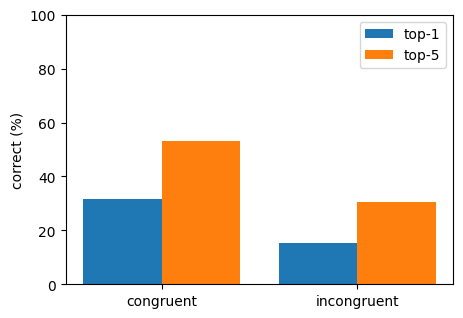

In [6]:
OBJECT_SIZE = 0.7

def accuracy(obj, scene_names):
    guesses = top5([paste(obj, s, OBJECT_SIZE) for s in scene_names])
    return (np.mean([g[0] in correct[obj] for g in guesses]),
            np.mean([any(x in correct[obj] for x in g) for g in guesses]))

results = {"congruent": [], "incongruent": []}
for obj in correct:
    for cond in ["congruent", "incongruent"]:
        results[cond].append(accuracy(obj, [p["scene"] for p in pairs if p["object"] == f"{obj}.png" and p["condition"] == cond]))
acc = {cond: np.mean(r, axis=0) * 100 for cond, r in results.items()}    # average over objects, in %

for cond, (t1, t5) in acc.items():
    print(f"{cond:12s} top-1 {t1:3.0f}%   top-5 {t5:3.0f}%")
x = np.arange(2)
plt.figure(figsize=(5, 3.5))
plt.bar(x - 0.2, [a[0] for a in acc.values()], 0.4, label="top-1")
plt.bar(x + 0.2, [a[1] for a in acc.values()], 0.4, label="top-5")
plt.xticks(x, list(acc)); plt.ylabel("correct (%)"); plt.ylim(0, 100); plt.legend(); plt.show()

## 2. Mirror confusion

People (and monkeys) confuse an object with its **left–right** mirror image more easily than with its **upside-down** mirror image.

Jacob et al. turn each effect into **one number per layer**: they compare two distances between activations (d1 and d2) with

**index = (d1 − d2) / (d1 + d2)**

The index lies between −1 and 1. It is **positive** if d1 is larger (the effect is present, as in humans), **around 0** if there is no difference.

Here d1 = distance between an image and its **upside-down** version, d2 = distance between the image and its **left–right** version. We use 48 of last week's images, plus each image turned by 90°, so that tall or wide objects don't decide the result.

48 images, e.g. ['animal_flamingo_1', 'animal_flamingo_2', 'animal_flamingo_3']


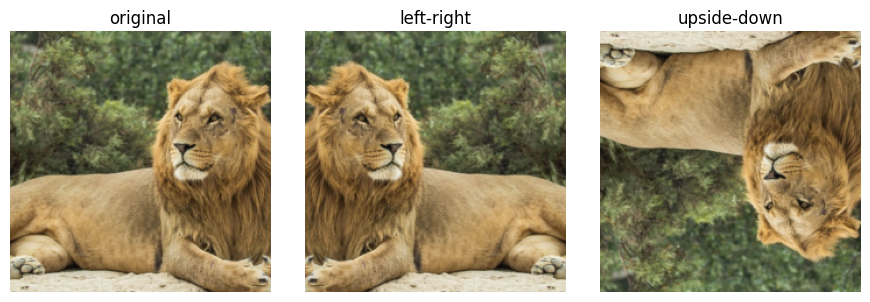

In [7]:
paths = sorted(p for p in IMAGE_DIR.iterdir() if p.suffix.lower() in {".jpg", ".jpeg", ".png"} and not p.name.startswith("."))
week4 = {p.stem: what_network_sees(Image.open(p).convert("RGB")) for p in paths}
print(f"{len(week4)} images, e.g. {list(week4)[:3]}")

EXAMPLE = "animal_lion_1"
img = week4[EXAMPLE]
versions = {"original": img, "left-right": img.transpose(Image.FLIP_LEFT_RIGHT), "upside-down": img.transpose(Image.FLIP_TOP_BOTTOM)}
fig, axes = plt.subplots(1, 3, figsize=(9, 3))
for ax, (name, v) in zip(axes, versions.items()):
    ax.imshow(v); ax.set_title(name); ax.axis("off")
plt.tight_layout(); plt.show()

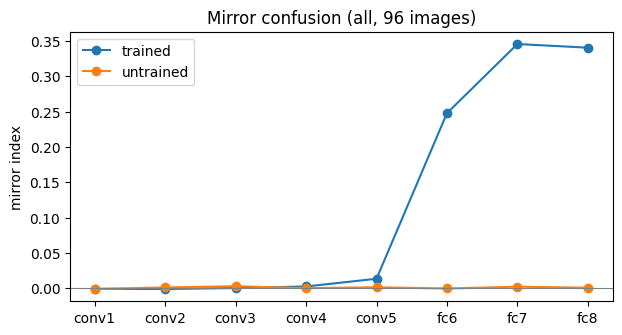

In [8]:
CONCEPT = "all"     # "all", or one concept, e.g. "lion", "banana", "violin"

chosen = [img for name, img in week4.items() if CONCEPT == "all" or name.split("_")[1] == CONCEPT]
base = chosen + [img.transpose(Image.ROTATE_90) for img in chosen]        # plus the 90° turned copies

mirror_index = {}
for net, model in NETWORKS.items():
    idx = {layer: [] for layer in LAYERS}
    for s in range(0, len(base), 20):                                     # 20 images at a time to save memory
        batch = base[s:s + 20]
        a = get_acts(model, batch)
        lr = get_acts(model, [b.transpose(Image.FLIP_LEFT_RIGHT) for b in batch])
        ud = get_acts(model, [b.transpose(Image.FLIP_TOP_BOTTOM) for b in batch])
        for layer in LAYERS:
            d_ud = np.linalg.norm(a[layer] - ud[layer], axis=1)
            d_lr = np.linalg.norm(a[layer] - lr[layer], axis=1)
            idx[layer] += list((d_ud - d_lr) / (d_ud + d_lr))
    mirror_index[net] = [np.mean(idx[layer]) for layer in LAYERS]

plot_layers(mirror_index, f"Mirror confusion ({CONCEPT}, {len(base)} images)", "mirror index")

#### Q1. Scene incongruence was measured from the network's guesses, mirror confusion from the activations inside the network. What can each kind of measure tell you that the other can't?

## 3. Bringing it together (with your partner)
#### Q2. Put your two plots from section 2 next to each other. How does training change each effect, and in which layers? Do these effects come from the network's architecture, from its training, or both?